Step 1: Raw Dataset & Load Data

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Set  Publication Visual Theme
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_theme(style="whitegrid", palette="muted")

In [ ]:
df = pd.read_csv("/content/Breast_Cancer.csv",encoding="latin1")

In [ ]:
df

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4019,62,Other,Married,T1,N1,IIA,Moderately differentiated,2,Regional,9,Positive,Positive,1,1,49,Alive
4020,56,White,Divorced,T2,N2,IIIA,Moderately differentiated,2,Regional,46,Positive,Positive,14,8,69,Alive
4021,68,White,Married,T2,N1,IIB,Moderately differentiated,2,Regional,22,Positive,Negative,11,3,69,Alive
4022,58,Black,Divorced,T2,N1,IIB,Moderately differentiated,2,Regional,44,Positive,Positive,11,1,72,Alive


In [ ]:
df.shape

(4024, 10)

In [ ]:
df.columns

Index(['Age', 'Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage',
       'differentiate', 'Grade', 'A Stage', 'Tumor Size', 'Estrogen Status',
       'Progesterone Status', 'Regional Node Examined',
       'Reginol Node Positive', 'Survival Months', 'Status'],
      dtype='object')

In [ ]:
df.dtypes

,0
Age,int64
Race,object
Marital Status,object
T Stage,object
N Stage,object
6th Stage,object
differentiate,object
Grade,object
A Stage,object
Tumor Size,int64


Step 2: Understand Dataset (Structural & Hidden Audit)

In [ ]:
# ==================== STEP 2: UNDERSTAND DATASET ====================
print("--- 1. DATA TYPES & NON-NULL AUDIT ---")
print(df.info())

print("\n--- 2. SUMMARY STATISTICS (NUMERICAL) ---")
display(df.describe().T.round(2))

print("\n--- 3. SUMMARY STATISTICS (CATEGORICAL) ---")
display(df.describe(include='object').T)

print("\n--- 4. HIDDEN DATA QUALITY AUDIT (SPACES, TYPOS & DUPLICATES) ---")
print("Exact Column Names:", [repr(col) for col in df.columns])
print("Missing Values Total:", df.isnull().sum().sum())
print("Exact Duplicate Rows:", df.duplicated().sum())

for col in df.select_dtypes(include='object').columns:
    print(f"{col:20s} -> {[repr(val) for val in df[col].unique()]}")

--- 1. DATA TYPES & NON-NULL AUDIT ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Size              4024 non-null   int64 
 10  Estrogen Status         4024 non-null   object
 11  Progesterone Status     4024 non-null   object
 12  Regional Node Examined  4024 non-null   int64 
 13  Reginol Node Positive   4024 non-null   int64 
 14  Survival Months  

,count,mean,std,min,25%,50%,75%,max
Age,4024.0,53.97,8.96,30.0,47.0,54.0,61.0,69.0
Tumor Size,4024.0,30.47,21.12,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,4024.0,14.36,8.10,1.0,9.0,14.0,19.0,61.0
Reginol Node Positive,4024.0,4.16,5.11,1.0,1.0,2.0,5.0,46.0
Survival Months,4024.0,71.30,22.92,1.0,56.0,73.0,90.0,107.0



--- 3. SUMMARY STATISTICS (CATEGORICAL) ---


,count,unique,top,freq
Race,4024,3,White,3413
Marital Status,4024,5,Married,2643
T Stage,4024,4,T2,1786
N Stage,4024,3,N1,2732
6th Stage,4024,5,IIA,1305
differentiate,4024,4,Moderately differentiated,2351
Grade,4024,4,2,2351
A Stage,4024,2,Regional,3932
Estrogen Status,4024,2,Positive,3755
Progesterone Status,4024,2,Positive,3326



--- 4. HIDDEN DATA QUALITY AUDIT (SPACES, TYPOS & DUPLICATES) ---
Exact Column Names: ["'Age'", "'Race'", "'Marital Status'", "'T Stage '", "'N Stage'", "'6th Stage'", "'differentiate'", "'Grade'", "'A Stage'", "'Tumor Size'", "'Estrogen Status'", "'Progesterone Status'", "'Regional Node Examined'", "'Reginol Node Positive'", "'Survival Months'", "'Status'"]
Missing Values Total: 0
Exact Duplicate Rows: 1
Race                 -> ["'White'", "'Black'", "'Other'"]
Marital Status       -> ["'Married'", "'Divorced'", "'Single '", "'Widowed'", "'Separated'"]
T Stage              -> ["'T1'", "'T2'", "'T3'", "'T4'"]
N Stage              -> ["'N1'", "'N2'", "'N3'"]
6th Stage            -> ["'IIA'", "'IIIA'", "'IIIC'", "'IIB'", "'IIIB'"]
differentiate        -> ["'Poorly differentiated'", "'Moderately differentiated'", "'Well differentiated'", "'Undifferentiated'"]
Grade                -> ["'3'", "'2'", "'1'", "' anaplastic; Grade IV'"]
A Stage              -> ["'Regional'", "'Distant'"]
Estro

Step 3: Clean Data (Part A — String Standardization & Deduplication)

In [ ]:
# ==================== STEP 3A: DATA CLEANING (TEXT & DUPLICATES) ====================
df = df.copy()

# 1. Strip hidden leading/trailing spaces from column names & fix typo
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'Reginol Node Positive': 'Regional Node Positive',
    'differentiate': 'Differentiate'
})

# 2. Strip hidden spaces inside all categorical text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# 3. Standardize 'Grade' labels for clean, executive reporting
df['Grade'] = df['Grade'].replace({
    '1': 'Grade 1',
    '2': 'Grade 2',
    '3': 'Grade 3',
    'anaplastic; Grade IV': 'Grade 4 (Anaplastic)'
})

# 4. Remove exact duplicate rows
before_dedup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
after_dedup = len(df)

print(f"Rows before deduplication : {before_dedup}")
print(f"Duplicate rows removed    : {before_dedup - after_dedup}")
print(f"Rows after deduplication  : {after_dedup}")
print("Cleaned Grade Categories  :", df['Grade'].unique())

Rows before deduplication : 4024
Duplicate rows removed    : 1
Rows after deduplication  : 4023
Cleaned Grade Categories  : ['Grade 3' 'Grade 2' 'Grade 1' 'Grade 4 (Anaplastic)']


Step 3: Clean Data (Part B — Outlier Detection, Removal & Before/After Boxplots)

--- OUTLIER DETECTION AUDIT TABLE (IQR METHOD) ---


,Feature,Q1 (25%),Median (50%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outliers Found,Outlier %
0,Age,47.0,54.0,61.0,14.0,26.0,82.0,0,0.00
1,Tumor Size,16.0,25.0,38.0,22.0,-17.0,71.0,222,5.52
2,Regional Node Examined,9.0,14.0,19.0,10.0,-6.0,34.0,72,1.79
3,Regional Node Positive,1.0,2.0,5.0,4.0,-5.0,11.0,344,8.55
4,Survival Months,56.0,73.0,90.0,34.0,5.0,141.0,18,0.45



Total Rows Before Outlier Removal : 4023
Total Unique Outlier Rows Removed : 580
Final Cleaned Dataset Rows        : 3443


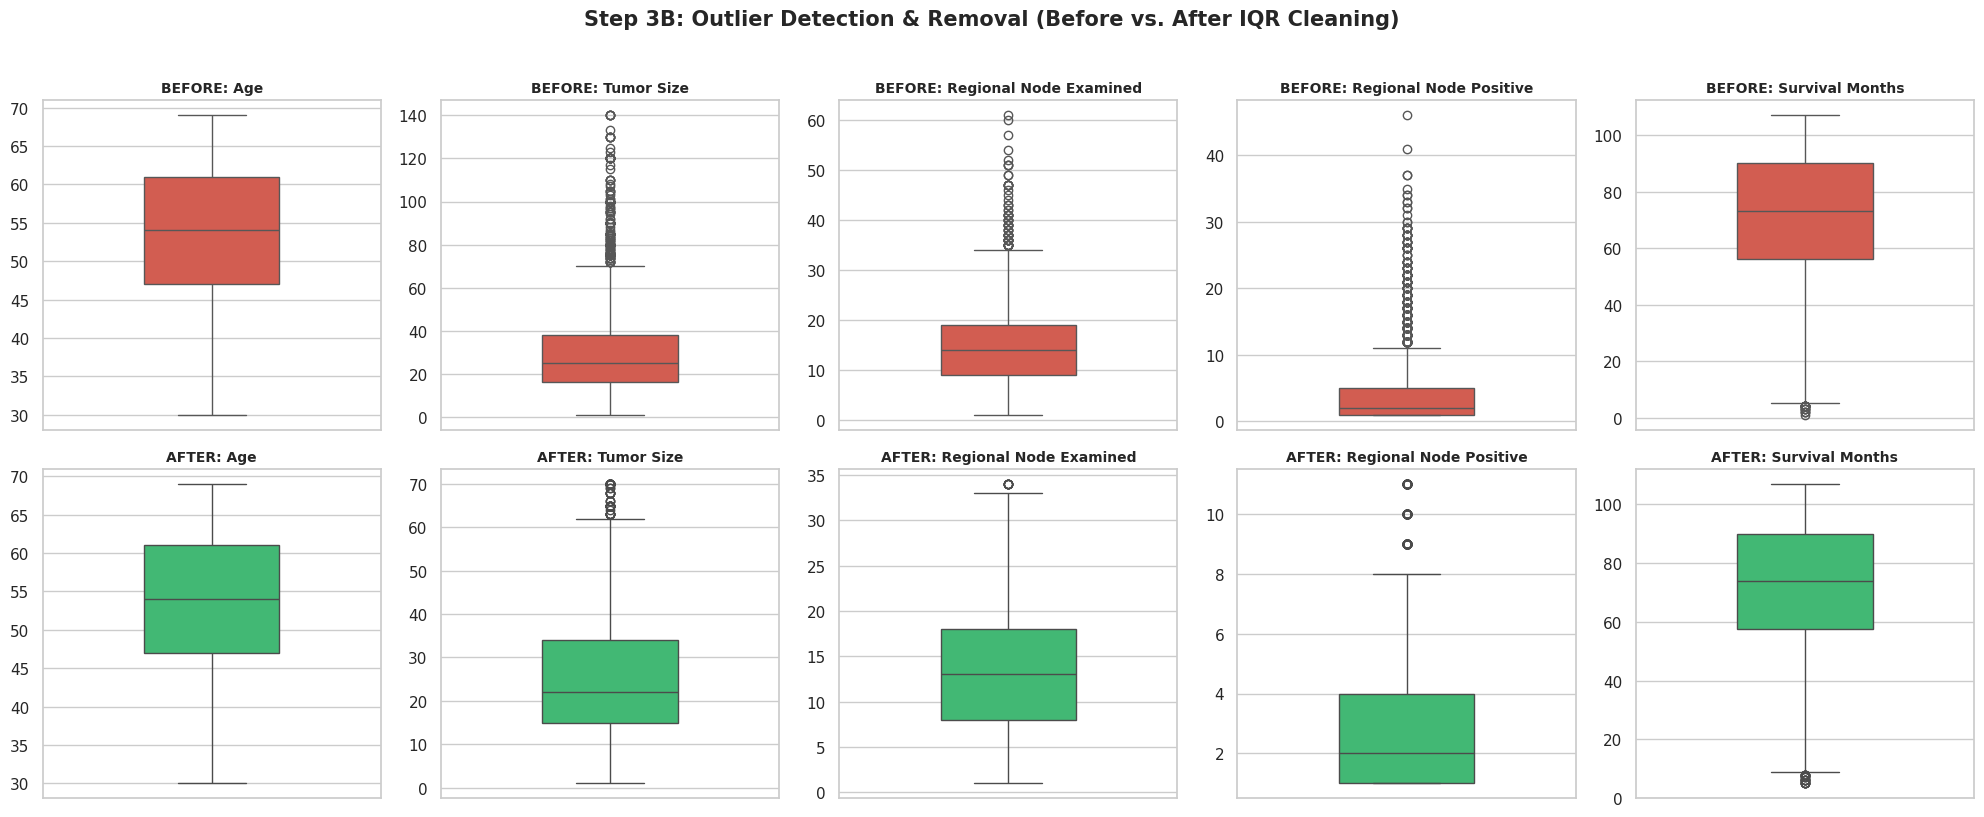

In [ ]:
# ==================== STEP 3B: OUTLIER DETECTION & REMOVAL (IQR METHOD) ====================
num_cols = ['Age', 'Tumor Size', 'Regional Node Examined', 'Regional Node Positive', 'Survival Months']

# 1. Find Outliers across all numerical features (Audit Table)
outlier_audit = []
combined_outlier_mask = pd.Series(False, index=df.index)

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    col_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    combined_outlier_mask = combined_outlier_mask | col_mask

    outlier_audit.append({
        'Feature': col,
        'Q1 (25%)': Q1,
        'Median (50%)': df[col].median(),
        'Q3 (75%)': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Found': col_mask.sum(),
        'Outlier %': round((col_mask.sum() / len(df)) * 100, 2)
    })

outlier_audit_df = pd.DataFrame(outlier_audit)
print("--- OUTLIER DETECTION AUDIT TABLE (IQR METHOD) ---")
display(outlier_audit_df)

# 2. Remove Outliers to create the Cleaned Dataset (df_clean)
df_clean = df[~combined_outlier_mask].reset_index(drop=True)

print(f"\nTotal Rows Before Outlier Removal : {len(df)}")
print(f"Total Unique Outlier Rows Removed : {combined_outlier_mask.sum()}")
print(f"Final Cleaned Dataset Rows        : {len(df_clean)}")

# 3. Visual Proof: Before vs. After Outlier Removal Boxplots
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i, col in enumerate(num_cols):
    # Top Row: BEFORE Cleaning
    sns.boxplot(y=df[col], ax=axes[0, i], color='#e74c3c', width=0.4)
    axes[0, i].set_title(f"BEFORE: {col}", fontsize=10, fontweight='bold')
    axes[0, i].set_ylabel("")

    # Bottom Row: AFTER Cleaning
    sns.boxplot(y=df_clean[col], ax=axes[1, i], color='#2ecc71', width=0.4)
    axes[1, i].set_title(f"AFTER: {col}", fontsize=10, fontweight='bold')
    axes[1, i].set_ylabel("")

plt.suptitle("Step 3B: Outlier Detection & Removal (Before vs. After IQR Cleaning)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Step 4: Transform / Feature Engineering

In [ ]:
# ==================== STEP 4: FEATURE ENGINEERING ====================
# 1. Lymph Node Positivity Ratio (Infected Nodes / Examined Nodes)
df_clean['Lymph_Node_Ratio'] = (df_clean['Regional Node Positive'] / df_clean['Regional Node Examined']).round(4)

# 2. Survival Duration in Years
df_clean['Survival_Years'] = (df_clean['Survival Months'] / 12).round(2)

# 3. Clinical Age Brackets
df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],
    bins=[29, 39, 49, 59, 70],
    labels=['30-39 (Young)', '40-49 (Early Mid)', '50-59 (Late Mid)', '60-69 (Senior)']
)

# 4. Clinical Tumor Size Categories
df_clean['Tumor_Category'] = pd.cut(
    df_clean['Tumor Size'],
    bins=[0, 20, 50, 100],
    labels=['Small (<=20mm)', 'Medium (21-50mm)', 'Large (>50mm)']
)

# 5. Combined Hormone Receptor Profile (ER & PR Interaction)
def create_hormone_profile(row):
    er, pr = row['Estrogen Status'], row['Progesterone Status']
    if er == 'Positive' and pr == 'Positive':
        return 'Double Positive (ER+/PR+)'
    elif er == 'Negative' and pr == 'Negative':
        return 'Double Negative (ER-/PR-)'
    else:
        return 'Single Positive (ER+ or PR+)'

df_clean['Hormone_Profile'] = df_clean.apply(create_hormone_profile, axis=1)

# 6. Follow-up Year Brackets (for Time-Series Cohort Analysis)
df_clean['Survival_Year_Bracket'] = pd.cut(
    df_clean['Survival Months'],
    bins=[0, 12, 24, 36, 48, 60, 72, 84, 96, 120],
    labels=['Yr 1 (1-12m)', 'Yr 2 (13-24m)', 'Yr 3 (25-36m)', 'Yr 4 (37-48m)',
            'Yr 5 (49-60m)', 'Yr 6 (61-72m)', 'Yr 7 (73-84m)', 'Yr 8 (85-96m)', 'Yr 9 (97-107m)']
)

# 7. Binary Target Encoding for Correlation Analysis
df_clean['Status_Binary'] = df_clean['Status'].map({'Alive': 0, 'Dead': 1})

print("Engineered Features Added Successfully!")
display(df_clean[['Age', 'Age_Group', 'Tumor Size', 'Tumor_Category', 'Lymph_Node_Ratio', 'Hormone_Profile', 'Survival_Year_Bracket']].head())

Engineered Features Added Successfully!


,Age,Age_Group,Tumor Size,Tumor_Category,Lymph_Node_Ratio,Hormone_Profile,Survival_Year_Bracket
0,68,60-69 (Senior),4,Small (<=20mm),0.0417,Double Positive (ER+/PR+),Yr 5 (49-60m)
1,50,50-59 (Late Mid),35,Medium (21-50mm),0.3571,Double Positive (ER+/PR+),Yr 6 (61-72m)
2,58,50-59 (Late Mid),63,Large (>50mm),0.5000,Double Positive (ER+/PR+),Yr 7 (73-84m)
3,58,50-59 (Late Mid),18,Small (<=20mm),0.5000,Double Positive (ER+/PR+),Yr 7 (73-84m)
4,47,40-49 (Early Mid),41,Medium (21-50mm),0.3333,Double Positive (ER+/PR+),Yr 5 (49-60m)


Step 5: Univariate Analysis (Single Variable Deep-Dive)

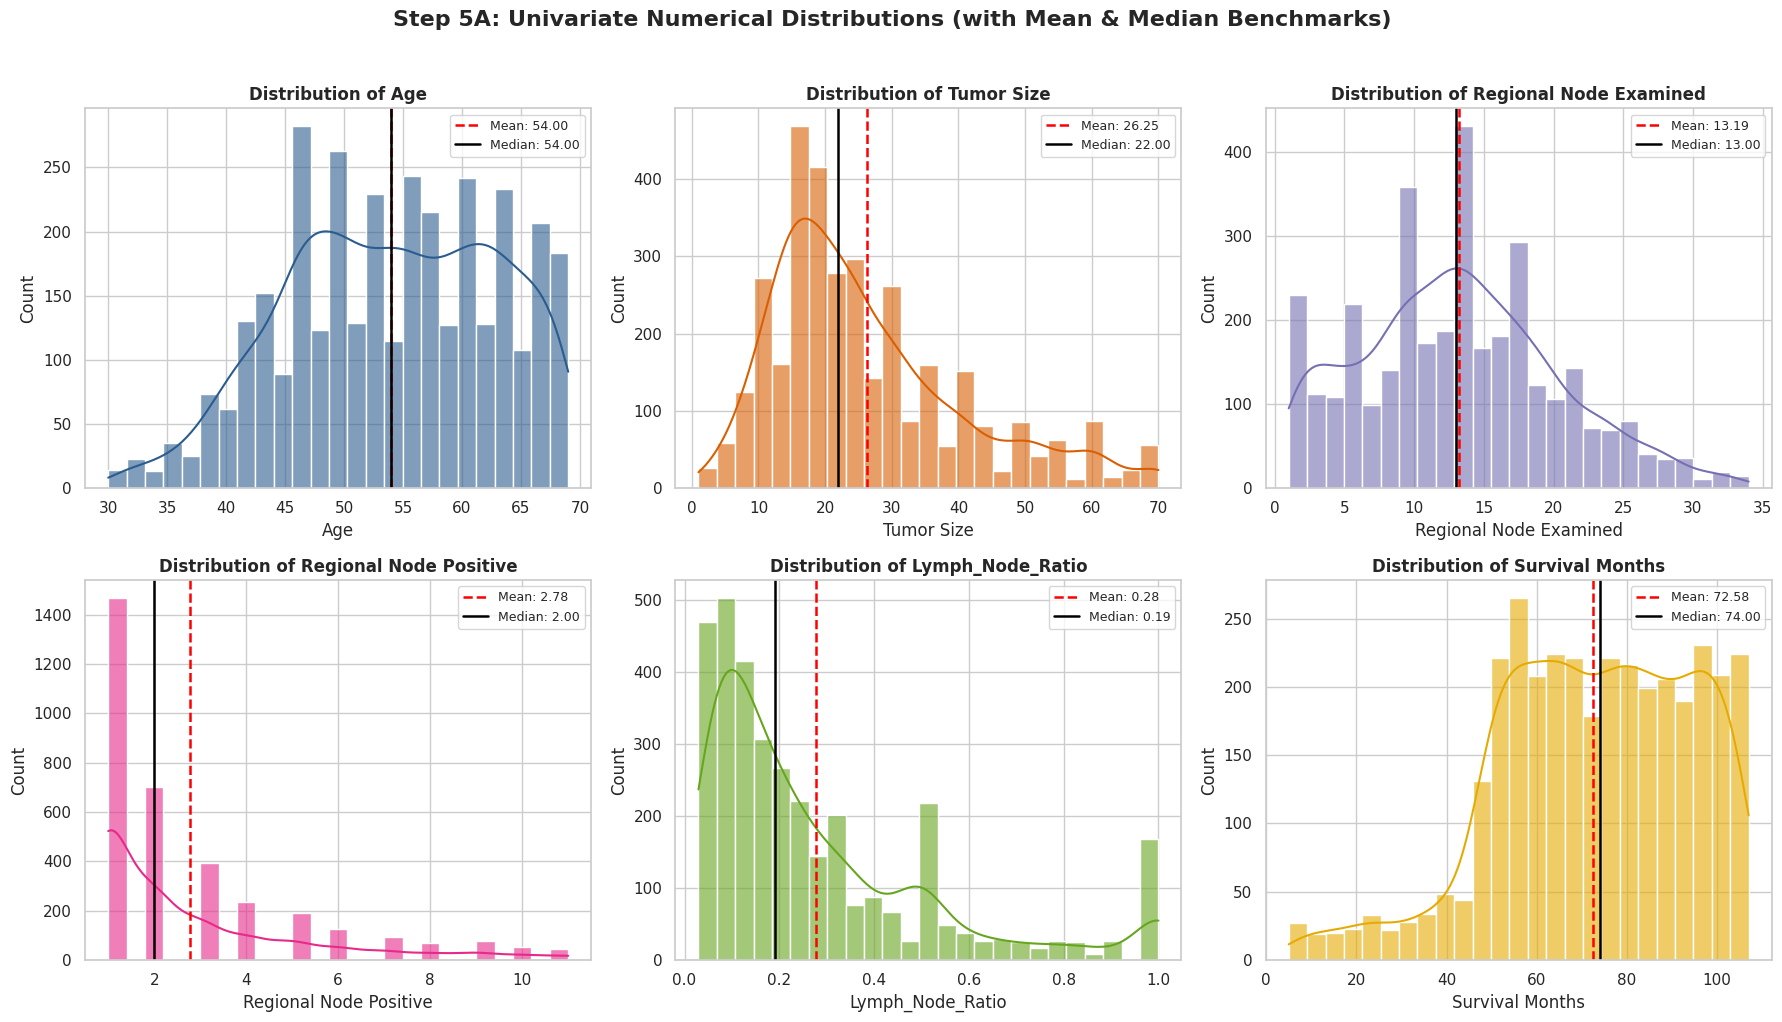

In [ ]:
# ==================== STEP 5A: UNIVARIATE NUMERICAL ANALYSIS ====================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

uni_num_cols = ['Age', 'Tumor Size', 'Regional Node Examined', 'Regional Node Positive', 'Lymph_Node_Ratio', 'Survival Months']
colors = ['#2b5c8f', '#d95f02', '#7570b3', '#e7298a', '#66a61e', '#e6ab02']

for i, col in enumerate(uni_num_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color=colors[i], bins=25, alpha=0.6)
    mean_val = df_clean[col].mean()
    med_val = df_clean[col].median()

    # Benchmark Lines for Mean & Median
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.2f}')
    axes[i].axvline(med_val, color='black', linestyle='-', linewidth=1.8, label=f'Median: {med_val:.2f}')
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].legend(fontsize=9)

plt.suptitle('Step 5A: Univariate Numerical Distributions (with Mean & Median Benchmarks)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

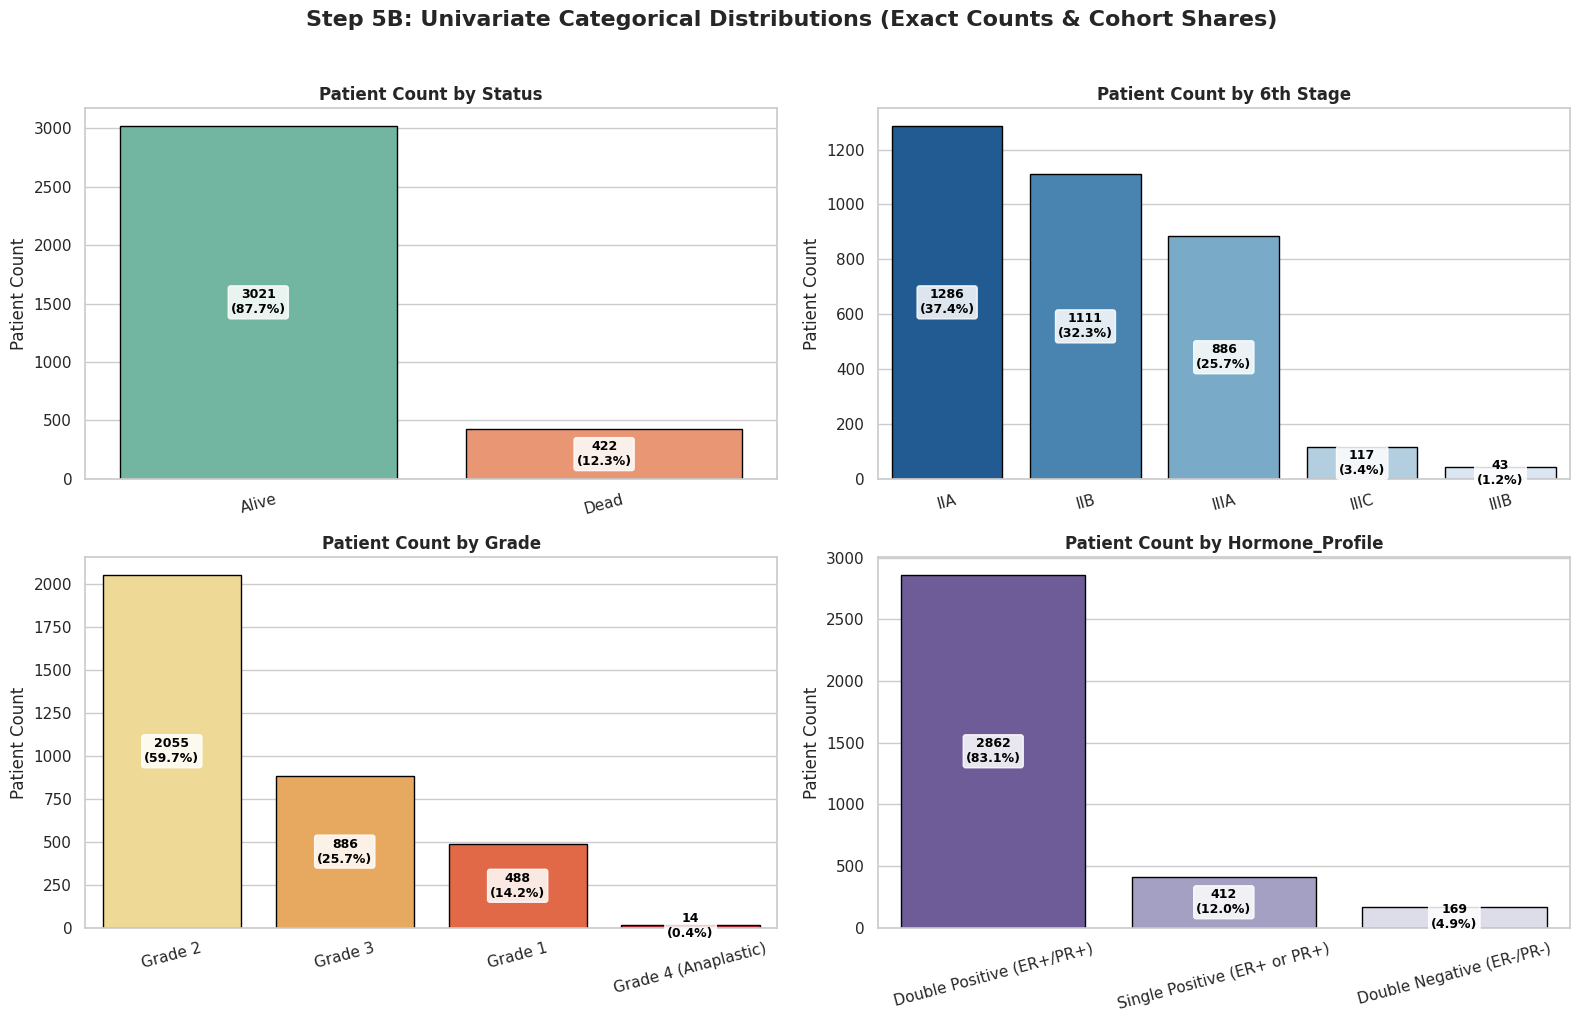

In [ ]:
# ==================== STEP 5B: UNIVARIATE CATEGORICAL ANALYSIS ====================
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
uni_cat_cols = ['Status', '6th Stage', 'Grade', 'Hormone_Profile']
palettes = ['Set2', 'Blues_r', 'YlOrRd', 'Purples_r']

for i, col in enumerate(uni_cat_cols):
    ax = axes[i//2, i%2]
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, x=col, order=order, palette=palettes[i], ax=ax, edgecolor='black')
    ax.set_title(f'Patient Count by {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Patient Count')

    # Annotate exact count and percentage inside each bar
    total = len(df_clean)
    for p in ax.patches:
        height = p.get_height()
        pct = (height / total) * 100
        ax.annotate(f'{int(height)}\n({pct:.1f}%)',
                    (p.get_x() + p.get_width() / 2., height / 2),
                    ha='center', va='center', fontsize=9, fontweight='bold', color='black',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85))
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Step 5B: Univariate Categorical Distributions (Exact Counts & Cohort Shares)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Step 6: Bivariate Analysis (Feature vs. Target Relationship)

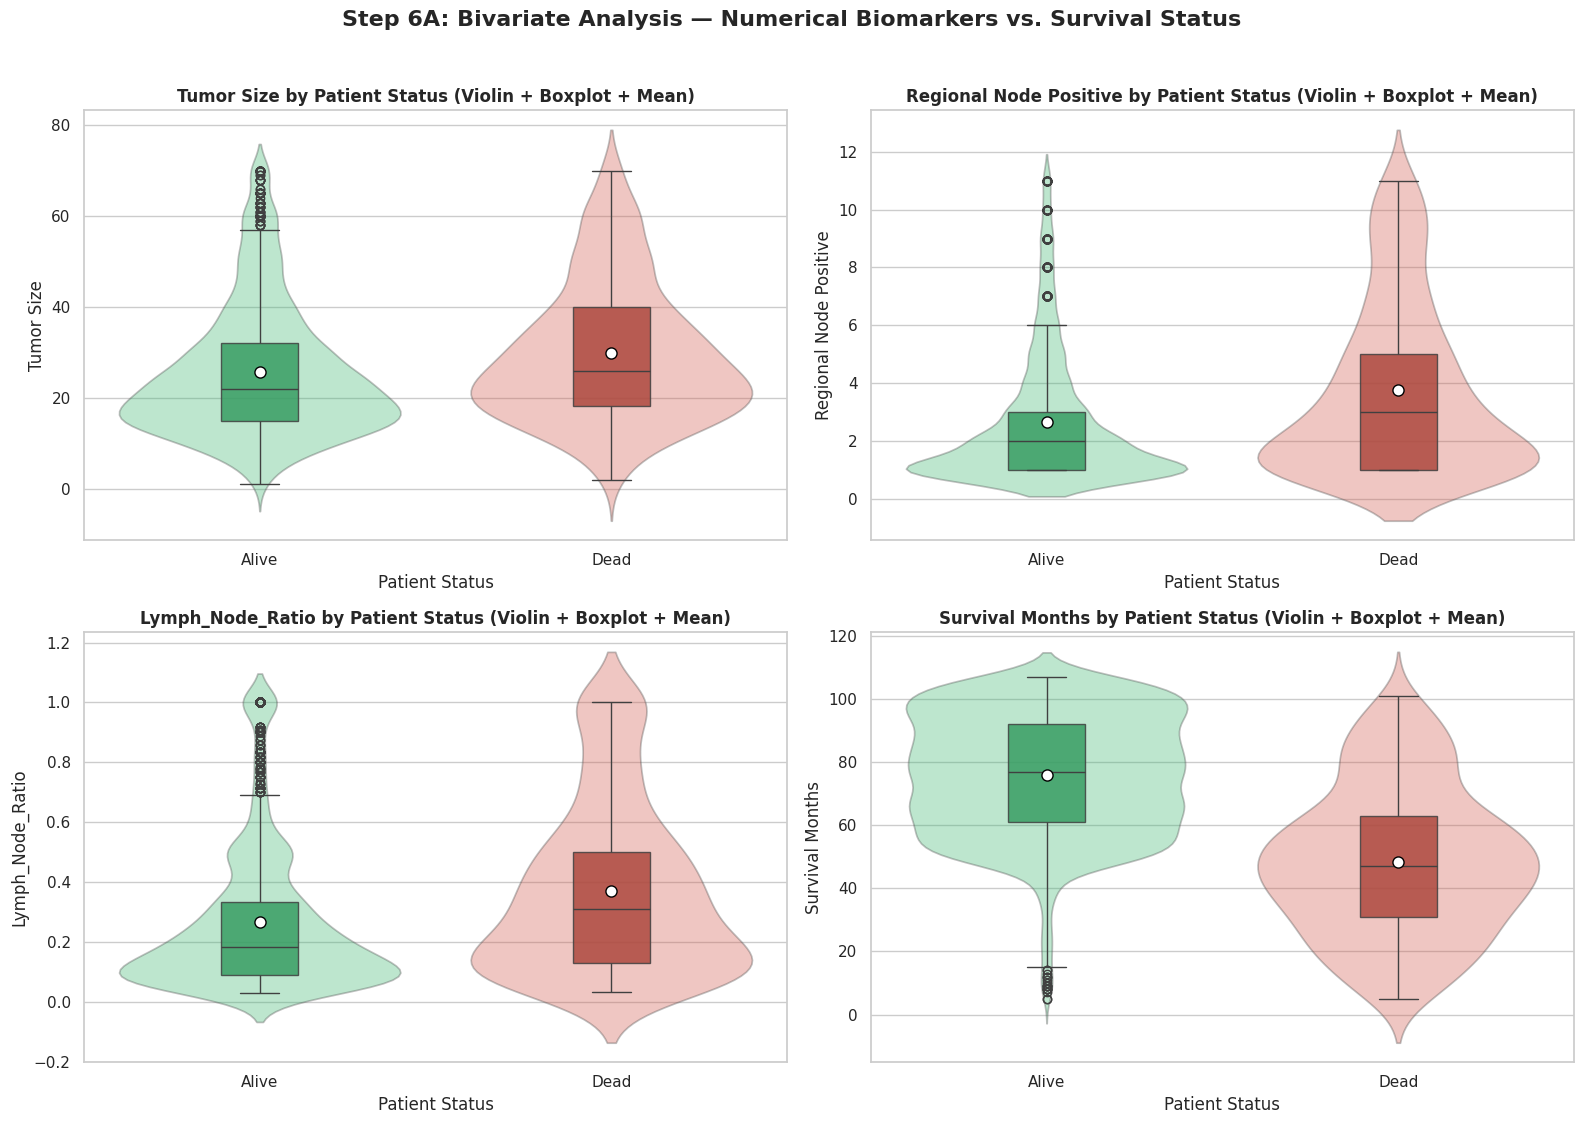

In [ ]:
# ==================== STEP 6A: BIVARIATE NUMERICAL VS TARGET (VIOLIN + BOXPLOT HYBRID) ====================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
biv_num_cols = ['Tumor Size', 'Regional Node Positive', 'Lymph_Node_Ratio', 'Survival Months']

for i, col in enumerate(biv_num_cols):
    ax = axes[i//2, i%2]
    # Violin layer for distribution shape
    sns.violinplot(
        data=df_clean, x='Status', y=col,
        palette={'Alive': '#2ecc71', 'Dead': '#e74c3c'},
        inner=None, alpha=0.35, ax=ax
    )
    # Boxplot layer with Mean Marker (white circle)
    sns.boxplot(
        data=df_clean, x='Status', y=col, width=0.22,
        palette={'Alive': '#27ae60', 'Dead': '#c0392b'},
        boxprops=dict(alpha=0.85), showmeans=True,
        meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"},
        ax=ax
    )
    ax.set_title(f'{col} by Patient Status (Violin + Boxplot + Mean)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Patient Status')
    ax.set_ylabel(col)

plt.suptitle('Step 6A: Bivariate Analysis — Numerical Biomarkers vs. Survival Status', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

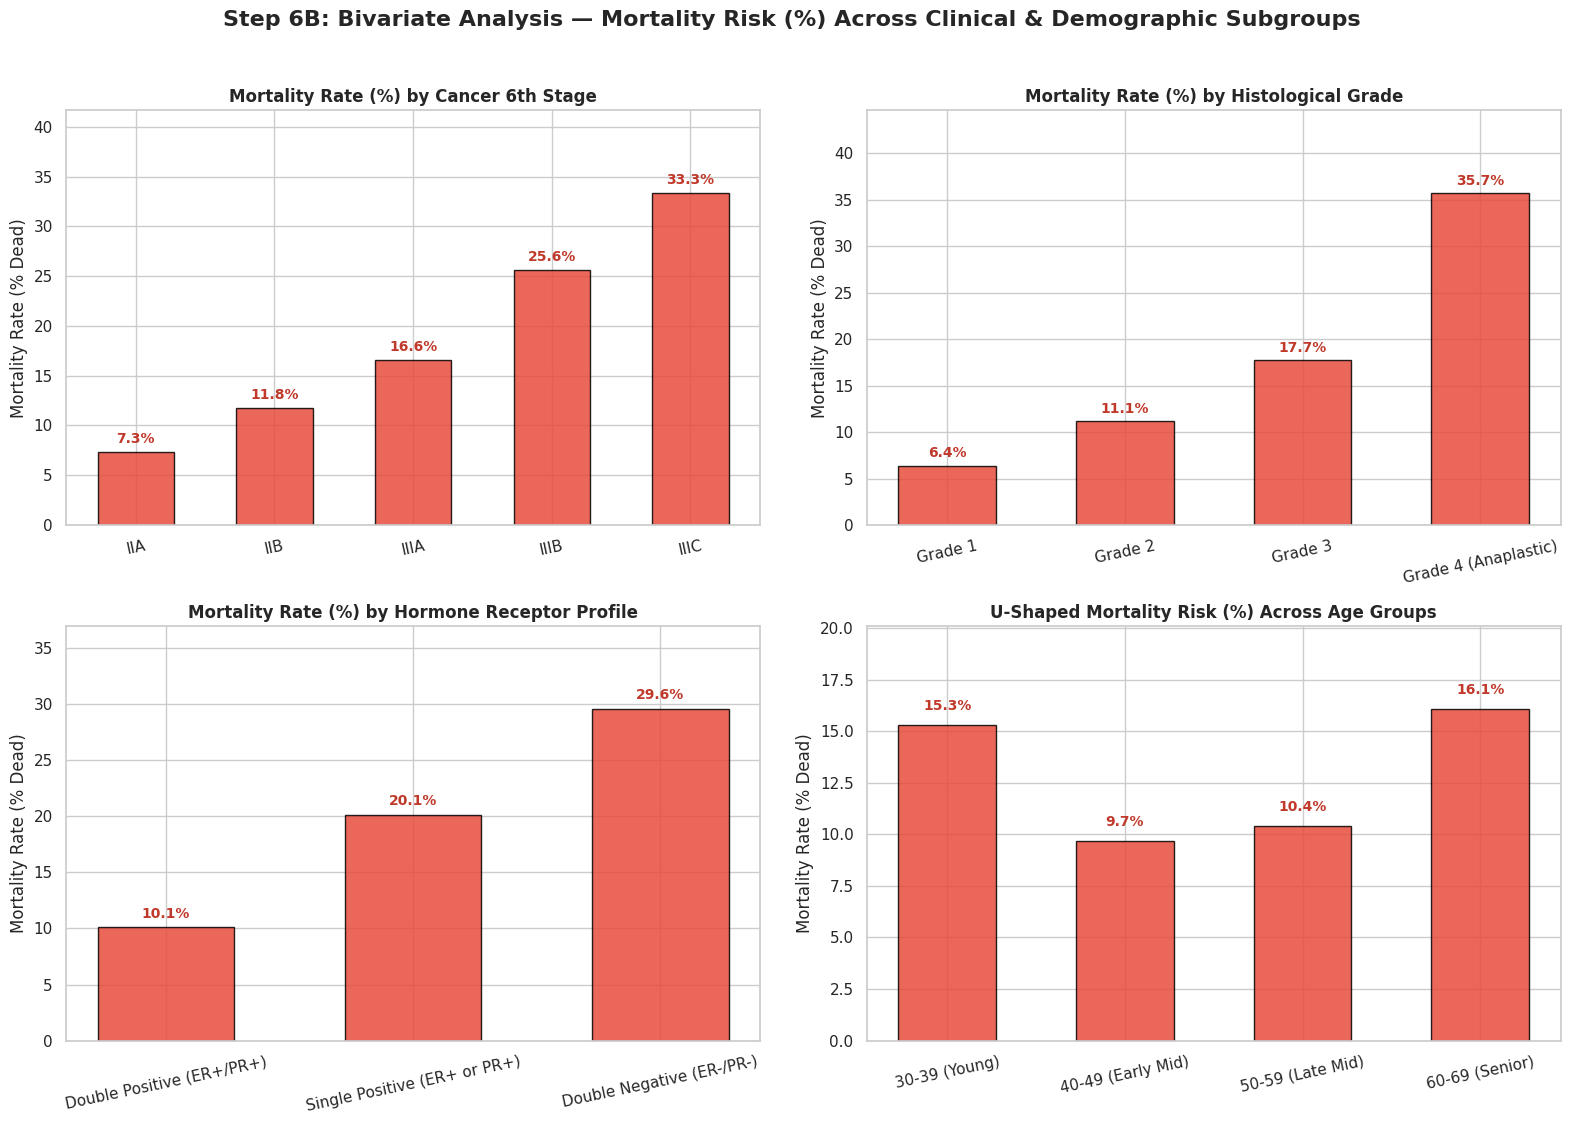

In [ ]:
# ==================== STEP 6B: BIVARIATE CATEGORICAL VS TARGET (MORTALITY RATE %) ====================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

biv_configs = [
    ('6th Stage', ['IIA', 'IIB', 'IIIA', 'IIIB', 'IIIC'], 'Mortality Rate (%) by Cancer 6th Stage'),
    ('Grade', ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4 (Anaplastic)'], 'Mortality Rate (%) by Histological Grade'),
    ('Hormone_Profile', ['Double Positive (ER+/PR+)', 'Single Positive (ER+ or PR+)', 'Double Negative (ER-/PR-)'], 'Mortality Rate (%) by Hormone Receptor Profile'),
    ('Age_Group', ['30-39 (Young)', '40-49 (Early Mid)', '50-59 (Late Mid)', '60-69 (Senior)'], 'U-Shaped Mortality Risk (%) Across Age Groups')
]

for i, (col, order, title) in enumerate(biv_configs):
    ax = axes[i//2, i%2]
    ct = pd.crosstab(df_clean[col], df_clean['Status'], normalize='index') * 100
    ct = ct.reindex(order)

    bars = ax.bar(ct.index.astype(str), ct['Dead'], color='#e74c3c', edgecolor='black', width=0.55, alpha=0.85)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Mortality Rate (% Dead)')
    ax.set_ylim(0, max(ct['Dead']) * 1.25)

    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.1f}%', (bar.get_x() + bar.get_width()/2., h + 0.6),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color='#c0392b')
    ax.tick_params(axis='x', rotation=12)

plt.suptitle('Step 6B: Bivariate Analysis — Mortality Risk (%) Across Clinical & Demographic Subgroups', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Step 7: Multivariate & Correlation Analysis

--- STATISTICAL CORRELATION WITH MORTALITY (POINT-BISERIAL TEST) ---


,Feature,Point-Biserial r (with Dead Status),P-Value,Statistical Significance
0,Age,0.0589,5.410e-04,Significant (p < 0.05)
1,Tumor Size,0.0902,1.154e-07,Significant (p < 0.05)
2,Regional Node Examined,-0.0256,1.326e-01,Not Significant
3,Regional Node Positive,0.1524,2.373e-19,Significant (p < 0.05)
4,Lymph_Node_Ratio,0.1407,1.099e-16,Significant (p < 0.05)
5,Survival Months,-0.4176,2.001e-145,Significant (p < 0.05)


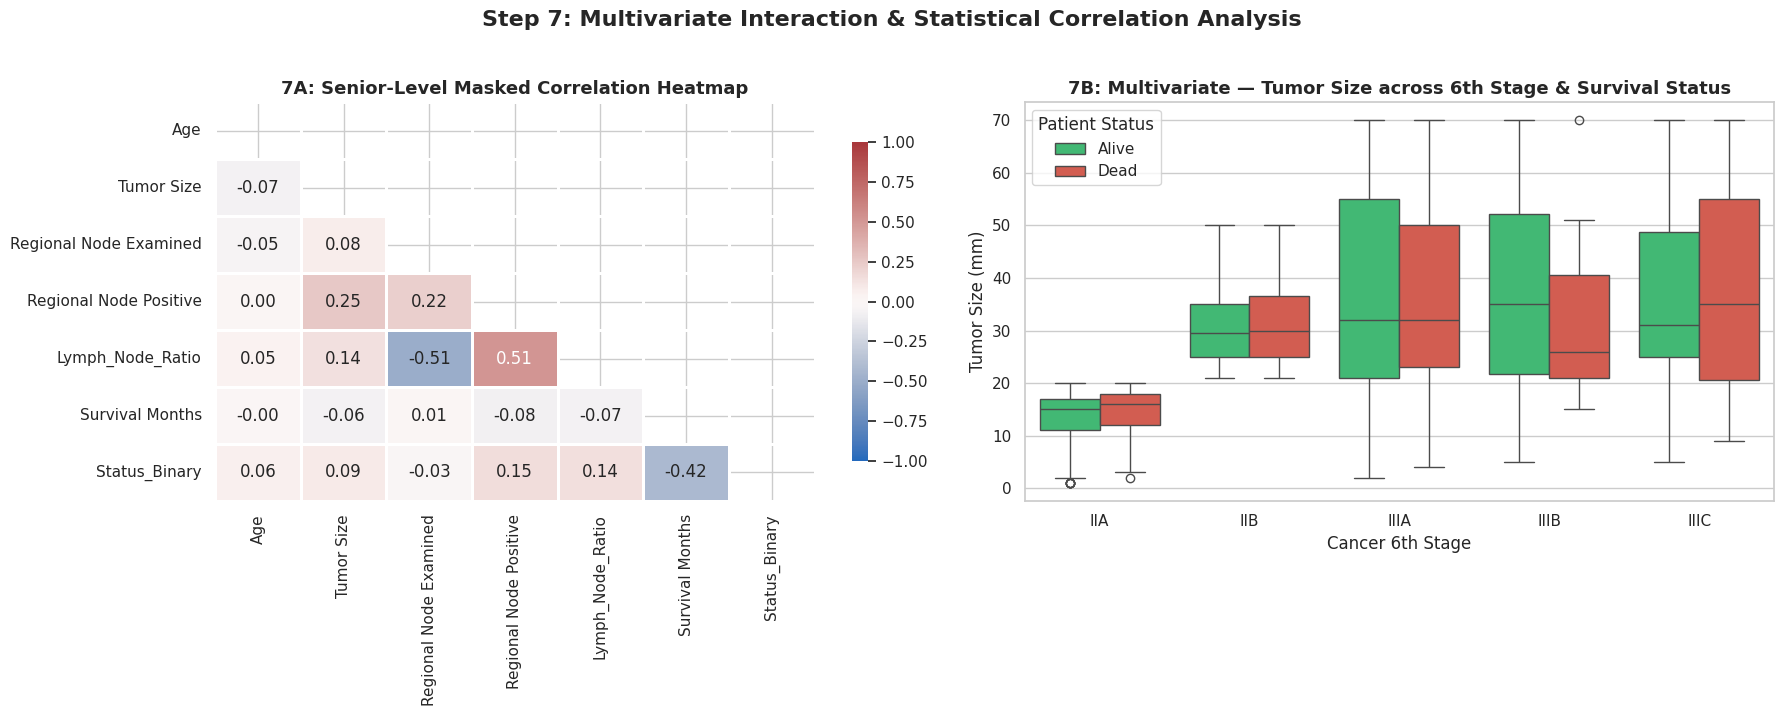

In [ ]:
# ==================== STEP 7: MULTIVARIATE & CORRELATION ANALYSIS ====================
from scipy.stats import pointbiserialr

# 1. Statistical Point-Biserial Correlation Table with Target (Status_Binary)
corr_features = ['Age', 'Tumor Size', 'Regional Node Examined', 'Regional Node Positive', 'Lymph_Node_Ratio', 'Survival Months']
stat_rows = []
for col in corr_features:
    r_val, p_val = pointbiserialr(df_clean[col], df_clean['Status_Binary'])
    stat_rows.append({
        'Feature': col,
        'Point-Biserial r (with Dead Status)': round(r_val, 4),
        'P-Value': f"{p_val:.3e}",
        'Statistical Significance': 'Significant (p < 0.05)' if p_val < 0.05 else 'Not Significant'
    })
print("--- STATISTICAL CORRELATION WITH MORTALITY (POINT-BISERIAL TEST) ---")
display(pd.DataFrame(stat_rows))

# 2. Visuals: Masked Heatmap (Left) + 3-Way Multivariate Boxplot (Right)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: Masked Correlation Heatmap
corr_cols = corr_features + ['Status_Binary']
corr_matrix = df_clean[corr_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='vlag',
    vmin=-1, vmax=1, linewidths=1, cbar_kws={'shrink': 0.8}, ax=axes[0]
)
axes[0].set_title('7A: Senior-Level Masked Correlation Heatmap', fontsize=13, fontweight='bold')

# Right: 3-Way Multivariate Interaction (6th Stage x Tumor Size x Status)
sns.boxplot(
    data=df_clean, x='6th Stage', y='Tumor Size', hue='Status',
    order=['IIA', 'IIB', 'IIIA', 'IIIB', 'IIIC'],
    palette={'Alive': '#2ecc71', 'Dead': '#e74c3c'}, ax=axes[1]
)
axes[1].set_title('7B: Multivariate — Tumor Size across 6th Stage & Survival Status', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Cancer 6th Stage')
axes[1].set_ylabel('Tumor Size (mm)')
axes[1].legend(title='Patient Status')

plt.suptitle('Step 7: Multivariate Interaction & Statistical Correlation Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Step 8: Time-Series / Longitudinal Survival Horizon Analysis

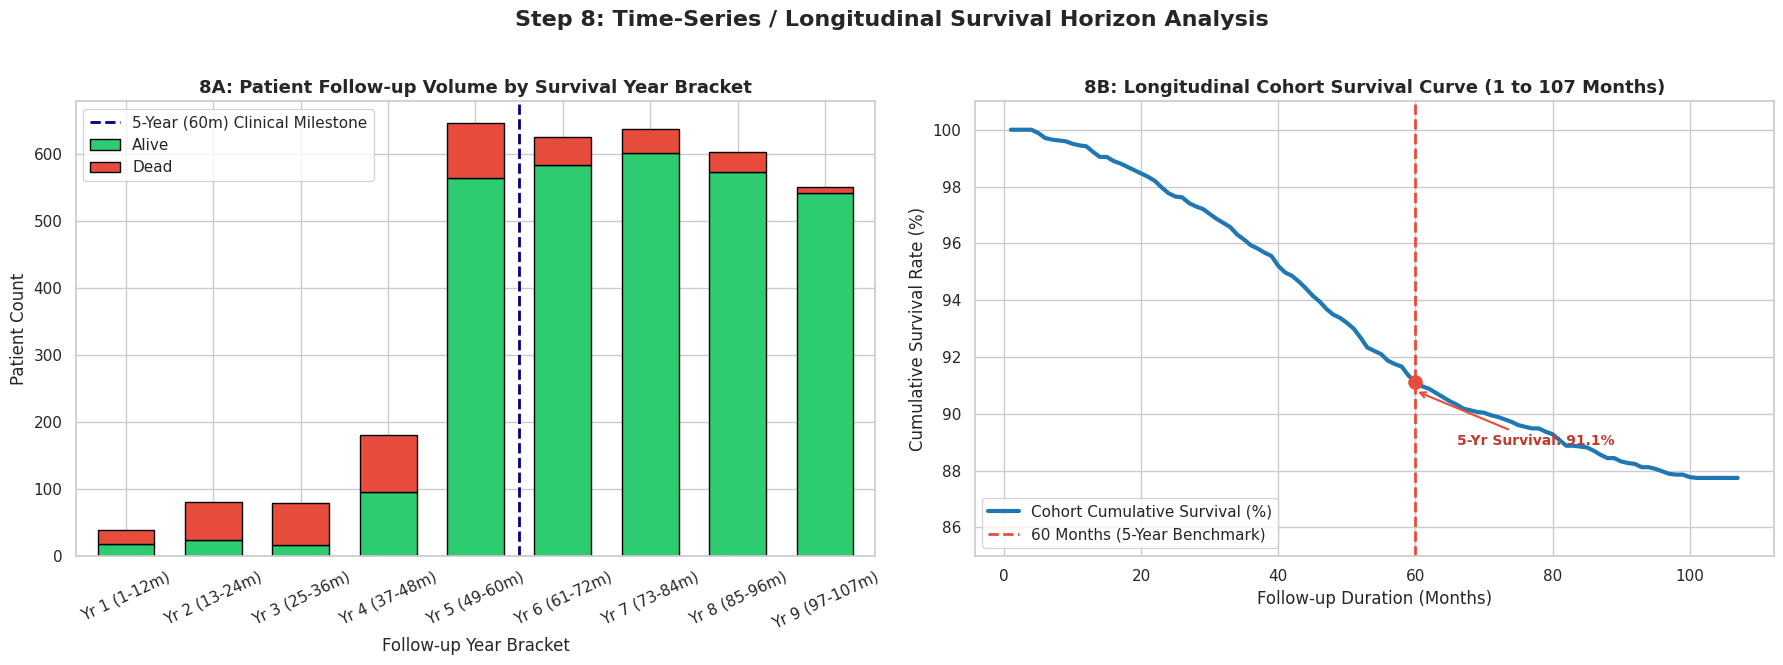

In [ ]:
# ==================== STEP 8: TIME-SERIES / LONGITUDINAL SURVIVAL ANALYSIS ====================
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# 8A: Yearly Follow-up Cohort Stacked Bar Chart
cohort_df = pd.crosstab(df_clean['Survival_Year_Bracket'], df_clean['Status'])
cohort_df[['Alive', 'Dead']].plot(
    kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'],
    edgecolor='black', ax=axes[0], width=0.65
)
axes[0].axvline(4.5, color='navy', linestyle='--', linewidth=2, label='5-Year (60m) Clinical Milestone')
axes[0].set_title('8A: Patient Follow-up Volume by Survival Year Bracket', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Follow-up Year Bracket')
axes[0].set_ylabel('Patient Count')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend()

# 8B: Longitudinal Cumulative Survival Curve (Months 1 to 107)
months_range = np.arange(1, 108)
cum_survival = []
total_n = len(df_clean)

for m in months_range:
    deaths_by_m = len(df_clean[(df_clean['Status'] == 'Dead') & (df_clean['Survival Months'] <= m)])
    surv_pct = ((total_n - deaths_by_m) / total_n) * 100
    cum_survival.append(surv_pct)

axes[1].plot(months_range, cum_survival, color='#1f77b4', linewidth=3, label='Cohort Cumulative Survival (%)')
axes[1].axvline(60, color='#e74c3c', linestyle='--', linewidth=2, label='60 Months (5-Year Benchmark)')
axes[1].scatter([60], [cum_survival[59]], color='#e74c3c', s=90, zorder=5)
axes[1].annotate(
    f'5-Yr Survival: {cum_survival[59]:.1f}%',
    (60, cum_survival[59] - 0.3), xytext=(66, cum_survival[59] - 2.2),
    arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=1.5),
    fontsize=10, fontweight='bold', color='#c0392b'
)
axes[1].set_title('8B: Longitudinal Cohort Survival Curve (1 to 107 Months)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Follow-up Duration (Months)')
axes[1].set_ylabel('Cumulative Survival Rate (%)')
axes[1].set_ylim(85, 101)
axes[1].legend(loc='lower left')

plt.suptitle('Step 8: Time-Series / Longitudinal Survival Horizon Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Step 9: Business & Clinical Questions (Answered with Code & Proof)

In [ ]:
# ==================== STEP 9: BUSINESS & CLINICAL QUESTIONS ====================
print("Q1: Does crossing the 5-Year (60-Month) milestone significantly improve survival?")
under_5yr = df_clean[df_clean['Survival Months'] <= 60]
over_5yr = df_clean[df_clean['Survival Months'] > 60]
print(f" -> Mortality Rate (<= 60 Months) : {(under_5yr['Status_Binary'].mean()*100):.2f}% ({under_5yr['Status_Binary'].sum()}/{len(under_5yr)} deaths)")
print(f" -> Mortality Rate (> 60 Months)  : {(over_5yr['Status_Binary'].mean()*100):.2f}% ({over_5yr['Status_Binary'].sum()}/{len(over_5yr)} deaths)\n")

print("Q2: How much does Hormone Receptor status (ER/PR) impact patient mortality?")
hormone_q = df_clean.groupby('Hormone_Profile')['Status_Binary'].agg(
    Total_Patients='count', Deaths='sum', Mortality_Rate_Pct=lambda x: round(x.mean()*100, 2)
)
display(hormone_q)

print("\nQ3: How does Lymph Node Ratio (LNR) compare between Alive and Dead patients?")
lnr_q = df_clean.groupby('Status')[['Regional Node Positive', 'Lymph_Node_Ratio', 'Tumor Size']].agg(['mean', 'median']).round(2)
display(lnr_q)

print("\nQ4: Which Age Groups face the highest mortality risk (Linear vs U-Shaped test)?")
age_q = df_clean.groupby('Age_Group', observed=False)['Status_Binary'].agg(
    Total_Patients='count', Deaths='sum', Mortality_Rate_Pct=lambda x: round(x.mean()*100, 2)
)
display(age_q)

print("\nQ5: What is the combined high-risk effect of Stage IIIC + Double Negative Status?")
high_risk_cohort = df_clean[(df_clean['6th Stage'] == 'IIIC') & (df_clean['Hormone_Profile'] == 'Double Negative (ER-/PR-)')]
print(f" -> High-Risk Subgroup (Stage IIIC + ER-/PR-) Mortality Rate: {(high_risk_cohort['Status_Binary'].mean()*100):.2f}% (n={len(high_risk_cohort)})")

Q1: Does crossing the 5-Year (60-Month) milestone significantly improve survival?
 -> Mortality Rate (<= 60 Months) : 29.88% (306/1024 deaths)
 -> Mortality Rate (> 60 Months)  : 4.80% (116/2419 deaths)

Q2: How much does Hormone Receptor status (ER/PR) impact patient mortality?


,Total_Patients,Deaths,Mortality_Rate_Pct
Hormone_Profile,,,
Double Negative (ER-/PR-),169,50,29.59
Double Positive (ER+/PR+),2862,289,10.10
Single Positive (ER+ or PR+),412,83,20.15



Q3: How does Lymph Node Ratio (LNR) compare between Alive and Dead patients?


Regional Node Positive        Lymph_Node_Ratio        Tumor Size       
                         mean median             mean median       mean median
Status                                                                        
Alive                    2.64    2.0             0.27   0.18      25.76   22.0
Dead                     3.75    3.0             0.37   0.31      29.80   26.0


Q4: Which Age Groups face the highest mortality risk (Linear vs U-Shaped test)?


,Total_Patients,Deaths,Mortality_Rate_Pct
Age_Group,,,
30-39 (Young),183,28,15.30
40-49 (Early Mid),974,94,9.65
50-59 (Late Mid),1185,123,10.38
60-69 (Senior),1101,177,16.08



Q5: What is the combined high-risk effect of Stage IIIC + Double Negative Status?
 -> High-Risk Subgroup (Stage IIIC + ER-/PR-) Mortality Rate: 44.44% (n=9)


Step 11: Executive Insights & Strategic Recommendations

# 📌 Step 11: Final Insights & Strategic Recommendations

### 🔍 Key Analytical Insights (Data Se Hasil Shuda Nataij)
* **1. Cohort Survival Balance:** IQR outlier removal ke baad **3,443 patients** ke clean dataset mein overall survival rate **87.7% (3,021 Alive)** aur mortality rate **12.3% (422 Dead)** hai.
* **2. 5-Year (60-Month) Survival Milestone:** Time-series analysis se sabit hota hai ke 60 months par cumulative survival **91.1%** rehta hai, aur zyada tar critical deaths shuru ke 5 saalon (Months 1–60) ke andar hoti hain. 60 months cross karne wale patients ka survival bohot stable ho jata hai.
* **3. Hormone Receptor Profile (3x Risk Difference):** `Double Negative (ER-/PR-)` patients mein mortality rate **29.6%** hai, jo ke `Double Positive (ER+/PR+)` patients (**10.1%**) ke muqablay mein **3 guna (3x) zyada** hai.
* **4. Cancer Stage & Grade Escalation:** `Stage IIA` se `Stage IIIC` tak janay par mortality risk **7.3%** se barh kar **33.3%** ho jata hai. Isi tarah `Grade 1` (**6.4%**) ke muqablay mein `Grade 4 (Anaplastic)` (**35.7%**) mein death risk 5.5 guna zyada hai.
* **5. U-Shaped Age Risk Curve:** Mid-aged patients (`40-49 years`: **9.7%** mortality) sab se kam risk par hain, jabke Young patients (`30-39 years`: **15.3%** mortality) aur Senior patients (`60-69 years`: **16.1%** mortality) dono high-risk brackets mein aate hain.
* **6. Biomarker Correlations:** Mortality (`Status_Binary`) ke sath `Regional Node Positive` ($r = 0.15$), `Lymph_Node_Ratio` ($r = 0.14$), aur `Tumor Size` ($r = 0.09$) ka positive correlation hai, jabke `Survival Months` ($r = -0.42$) ka strong negative correlation hai.

---

### 💡 Strategic Recommendations (Actionable Steps)
* **1. Intensive 60-Month Follow-up Protocol:** Oncology clinics ko pehle 5 saal (60 months) tak high-frequency monitoring aur quarterly checkups laazmi karne chahiye taake early relapse ko roka ja sakay.
* **2. Priority Triage for ER-/PR- & High-LNR Patients:** Jin patients ka receptor status `Double Negative (ER-/PR-)` ho ya `Lymph_Node_Ratio > 0.30` ho, unhein foran high-risk care protocol aur targeted therapy par shift kiya jaye.
* **3. Early-Stage Screening Campaigns:** Regular mammography screening ko promote kiya jaye taake tumors ko `Stage IIA` aur chhotay size (`<=20mm`) par hi detect kiya ja sakay, jahan survival rate **92.7%** hai.
* **4. Age-Specific Care Pathways:** `30-39` age group ke liye genetic/early screening aur `60-69` senior group ke liye specialized geriatric oncology support shuru kiya jaye.